# Item-level forecast and discount business value

Existing July 1, 2026 forecasts are historical demonstrations. Unit lifts are hypothetical, not modeled promotion responses. No model is retrained. Full-list-price no-discount GP is a reference, not expected GP under the actual historical discount policy. No profit floor is guaranteed.

See `reports/item_discount_scenarios/REPORT.md` for formulas, caveats and location-model feasibility.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
OUT=ROOT/'reports/item_discount_scenarios'
history=pd.read_csv(OUT/'historical_product_economics.csv')
forecast=pd.read_csv(OUT/'forecast_reference.csv')
scenarios=pd.read_csv(OUT/'discount_scenarios.csv')
print('135 branch/products; 4860 hypothetical scenarios. Inputs generated without training.')
display(history)
display(forecast[['Branch','Product','forecast_units','price','cost','ForecastNoDiscountGPUSD']])

135 branch/products; 4860 hypothetical scenarios. Inputs generated without training.


,Branch,Product,HistoricalUnits,HistoricalRevenueUSD,HistoricalGPUSD,HistoricalRecordedCostUSD,HistoricalTransactionCount,HistoricalGPPerUnitUSD,HistoricalUnitsPerCalendarDay
0,Garden,Almond Croissant,377,1818.17,788.96,1029.21,358,2.092732,2.082873
1,Garden,Americano,341,1069.49,718.26,351.23,327,2.106334,1.883978
2,Garden,Avocado Toast,305,2860.43,1036.53,1823.90,282,3.398459,1.685083
3,Garden,Banana Bread,416,1839.51,903.51,936.00,391,2.171899,2.298343
4,Garden,Blueberry Muffin,319,1253.79,657.26,596.53,294,2.060376,1.762431
...,...,...,...,...,...,...,...,...,...
130,Uptown,Strawberry Matcha,281,2053.78,1196.73,857.05,265,4.258826,1.552486
131,Uptown,Tiramisu Cup,163,1020.86,574.24,446.62,148,3.522945,0.900552
132,Uptown,Tuna Sandwich,181,1534.25,886.27,647.98,167,4.896519,1.000000
133,Uptown,Turkey & Cheese Sandwich,276,2536.25,1285.97,1250.28,265,4.659312,1.524862


,Branch,Product,forecast_units,price,cost,ForecastNoDiscountGPUSD
0,Garden,Almond Croissant,2.179347,4.85,2.73,4.620215
1,Garden,Americano,2.207049,3.15,1.03,4.678944
2,Garden,Avocado Toast,2.258471,9.45,5.98,7.836893
3,Garden,Banana Bread,2.727619,4.45,2.25,6.000763
4,Garden,Blueberry Muffin,2.063923,3.95,1.87,4.292959
...,...,...,...,...,...,...
130,Uptown,Strawberry Matcha,2.460669,7.34,3.05,10.556268
131,Uptown,Tiramisu Cup,1.125294,6.29,2.74,3.994794
132,Uptown,Tuna Sandwich,1.171281,8.50,3.58,5.762703
133,Uptown,Turkey & Cheese Sandwich,1.729033,9.26,4.53,8.178328


## Examine any branch/product

Change the two selectors and rerun this cell. Historical GP/unit is observed. Forecast quantity is estimated. Discount/lift GP is conditional accounting with all modeled product units discounted, no waste or incremental operating costs. The minimum extra units and break-even discount limits do not predict that demand is attainable.

In [2]:
BRANCH='Garden'
PRODUCT='Chicken Pesto Sandwich'
display(history[(history.Branch==BRANCH)&(history.Product==PRODUCT)])
selected=scenarios[(scenarios.Branch==BRANCH)&(scenarios.Product==PRODUCT)]
display(selected[['DiscountFraction','AssumedUnitLift','ScenarioUnits','ScenarioGPUSD','GPChangeUSD','RequiredUnitLift','RequiredExtraUnits','MinimumWholeUnitsToPreserveGP','MaxDiscountAtAssumedLift','PreservesReferenceGP']].round(4))

,Branch,Product,HistoricalUnits,HistoricalRevenueUSD,HistoricalGPUSD,HistoricalRecordedCostUSD,HistoricalTransactionCount,HistoricalGPPerUnitUSD,HistoricalUnitsPerCalendarDay
11,Garden,Chicken Pesto Sandwich,354,3779.81,1163.75,2616.06,338,3.287429,1.955801


,DiscountFraction,AssumedUnitLift,ScenarioUnits,ScenarioGPUSD,GPChangeUSD,RequiredUnitLift,RequiredExtraUnits,MinimumWholeUnitsToPreserveGP,MaxDiscountAtAssumedLift,PreservesReferenceGP
396,0.00,0.00,2.7046,9.0875,0.0000,0.0000,0.0000,3.0,0.0000,True
397,0.00,0.05,2.8398,9.5419,0.4544,0.0000,0.0000,3.0,0.0149,True
398,0.00,0.10,2.9751,9.9963,0.9088,0.0000,0.0000,3.0,0.0284,True
399,0.00,0.20,3.2455,10.9050,1.8175,0.0000,0.0000,3.0,0.0521,True
400,0.00,0.30,3.5160,11.8138,2.7263,0.0000,0.0000,3.0,0.0721,True
401,0.00,0.50,4.0569,13.6313,4.5438,0.0000,0.0000,3.0,0.1042,True
402,0.05,0.00,2.7046,7.6338,-1.4537,0.1904,0.5151,4.0,0.0000,False
403,0.05,0.05,2.8398,8.0155,-1.0720,0.1904,0.5151,4.0,0.0149,False
404,0.05,0.10,2.9751,8.3972,-0.6904,0.1904,0.5151,4.0,0.0284,False
405,0.05,0.20,3.2455,9.1605,0.0730,0.1904,0.5151,4.0,0.0521,True


## Compare branch break-even requirements at 10% off

A positive unit margin is insufficient to preserve total GP. A discount with no additional units lowers this reference. Extra-unit requirements are more demanding where recorded margins are lower; reconcile Garden costing before assuming avoidable cash costs.

,Branch,Product,BaselineForecastUnits,NoDiscountReferenceGPUSD,DiscountedUnitGPUSD,RequiredUnitLift,RequiredExtraUnits
408,Garden,Chicken Pesto Sandwich,2.704619,9.087519,2.285,0.470460,1.272414
1020,Garden,Iced Latte,5.571390,16.602742,2.445,0.218814,1.219098
2028,Harbour,Chicken Pesto Sandwich,3.791264,23.202538,4.991,0.226207,0.857611
2640,Harbour,Iced Latte,9.292623,36.798789,3.398,0.165391,1.536920
3648,Uptown,Chicken Pesto Sandwich,1.772620,9.501244,4.328,0.238447,0.422677
4260,Uptown,Iced Latte,2.902725,10.304676,3.036,0.169302,0.491436


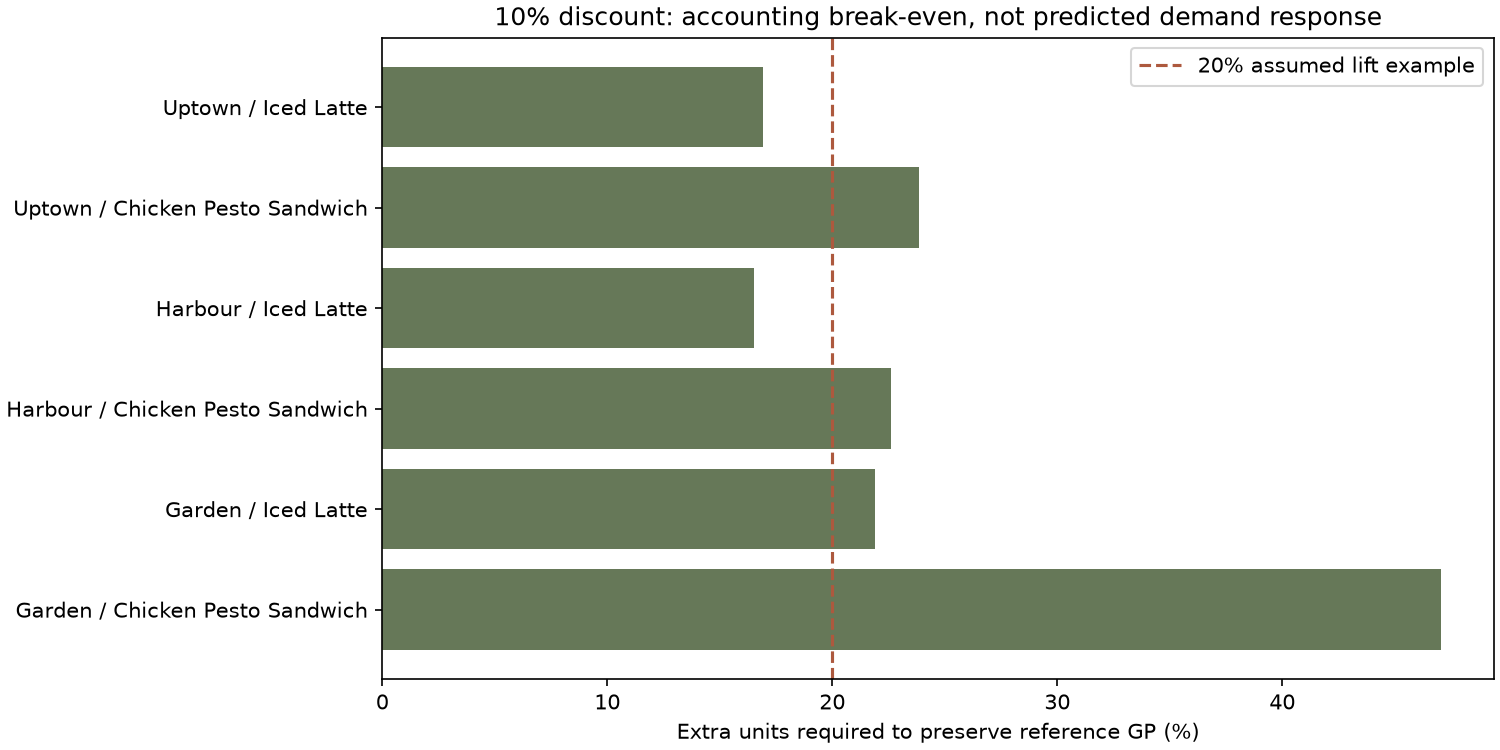

In [3]:
example=scenarios[(scenarios.DiscountFraction==.1)&(scenarios.AssumedUnitLift==0)&scenarios.Product.isin(['Iced Latte','Chicken Pesto Sandwich'])]
display(example[['Branch','Product','BaselineForecastUnits','NoDiscountReferenceGPUSD','DiscountedUnitGPUSD','RequiredUnitLift','RequiredExtraUnits']])
import os
os.environ.setdefault('MPLCONFIGDIR','/tmp/stories-matplotlib')
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
labels=[r.Branch+' / '+r.Product for r in example.itertuples()]
ax.barh(labels,example.RequiredUnitLift*100,color='#667858')
ax.axvline(20,color='#ad593e',linestyle='--',label='20% assumed lift example')
ax.set_xlabel('Extra units required to preserve reference GP (%)')
ax.set_title('10% discount: accounting break-even, not predicted demand response')
ax.legend()
p=ROOT/'figures/item_discount_scenarios';p.mkdir(exist_ok=True)
fig.savefig(p/'required_unit_lift.png',dpi=150);plt.close(fig)
display(Image(filename=str(p/'required_unit_lift.png')))

## How location context fits

Bliss Street/AUB and LeMall Dbayeh are separately sourced research cases, not mapped to Garden/Harbour/Uptown. Context rules can suggest audiences to investigate, but a trained location/offer-response model requires verified branch mapping and observed offer exposures/responses. Do not assign these anonymous forecasts to real-world places.

To measure incremental profit, prospectively randomize eligible opportunities, include nonbuyers and all basket purchases, and account for service, campaign, waste, capacity and cannibalization costs. The analysis does not activate an offer or demonstrate causal uplift.

In [4]:
assert len(history)==135 and len(forecast)==135 and len(scenarios)==4860
assert (scenarios[(scenarios.DiscountFraction>0)&(scenarios.AssumedUnitLift==0)].GPChangeUSD<0).all()
p=scenarios[scenarios.DiscountedUnitGPUSD>0]
np.testing.assert_allclose(p.RequiredUnitsToPreserveGP*p.DiscountedUnitGPUSD,p.NoDiscountReferenceGPUSD)
print('PASS accounting identities. No response model, guaranteed gain, active offer or causal inference.')

PASS accounting identities. No response model, guaranteed gain, active offer or causal inference.
